In [14]:
# import required libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [5]:
# load the kaggle dataset
df = pd.read_csv("students_stress_dataset_age_balanced.csv")
df.head()

,Resp_ID,Age,Gender,Academic_Level,Field_of_Study,Institution_Type,Avg_Daily_Study_Hours,B1_Pressure_High_Grades,B2_Workload_Overwhelming,B3_Balance_Difficult,...,D1_Headaches_Pain,D2_Appetite_Change,D3_Sleep_Trouble,D4_Isolation,D5_Unhealthy_Coping,E1_Stress_Frequency,E2_Overall_Stress,E3_Sought_Professional_Help,E4_Affects_Academic_Performance,Perceived_Stress_Index_0_100
0,1,19,Female,Graduate,Business,Public University,2–4,2,2,3,...,1,3,2,1,2,2,1,No,No,25.0
1,2,24,Male,Undergraduate,Computer Science,Public University,4–6,4,4,5,...,4,2,4,4,4,5,4,No,No,73.8
2,3,30,Male,Graduate,Social Science,Public University,<2,3,2,4,...,2,2,2,3,3,3,2,Yes,Yes,43.8
3,4,18,Female,Undergraduate,Computer Science,Public University,2–4,1,2,2,...,2,2,2,3,1,2,2,No,No,23.8
4,5,26,Female,Undergraduate,Science,Public University,>6,1,2,3,...,2,4,2,3,1,2,2,No,Yes,31.2


In [6]:
df.shape

(1000, 30)

In [8]:
print(df.columns.tolist())

['Resp_ID', 'Age', 'Gender', 'Academic_Level', 'Field_of_Study', 'Institution_Type', 'Avg_Daily_Study_Hours', 'B1_Pressure_High_Grades', 'B2_Workload_Overwhelming', 'B3_Balance_Difficult', 'B4_Sufficient_Sleep', 'B5_Procrastination', 'B6_Physical_Activity', 'B7_Excessive_Social_Media', 'C1_Anxious_Academics', 'C2_Concentration_Hard', 'C3_Mood_Swings', 'C4_Mentally_Exhausted', 'C5_Worry_Future', 'C6_Hopelessness_Sadness', 'D1_Headaches_Pain', 'D2_Appetite_Change', 'D3_Sleep_Trouble', 'D4_Isolation', 'D5_Unhealthy_Coping', 'E1_Stress_Frequency', 'E2_Overall_Stress', 'E3_Sought_Professional_Help', 'E4_Affects_Academic_Performance', 'Perceived_Stress_Index_0_100']


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 30 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Resp_ID                          1000 non-null   int64  
 1   Age                              1000 non-null   int64  
 2   Gender                           1000 non-null   object 
 3   Academic_Level                   1000 non-null   object 
 4   Field_of_Study                   1000 non-null   object 
 5   Institution_Type                 1000 non-null   object 
 6   Avg_Daily_Study_Hours            1000 non-null   object 
 7   B1_Pressure_High_Grades          1000 non-null   int64  
 8   B2_Workload_Overwhelming         1000 non-null   int64  
 9   B3_Balance_Difficult             1000 non-null   int64  
 10  B4_Sufficient_Sleep              1000 non-null   int64  
 11  B5_Procrastination               1000 non-null   int64  
 12  B6_Physical_Activity 

In [10]:
# check for duplicate rows
print("\nnumber of duplicate rows:", df.duplicated().sum())


number of duplicate rows: 0


In [11]:
df.describe()

,Resp_ID,Age,B1_Pressure_High_Grades,B2_Workload_Overwhelming,B3_Balance_Difficult,B4_Sufficient_Sleep,B5_Procrastination,B6_Physical_Activity,B7_Excessive_Social_Media,C1_Anxious_Academics,...,C5_Worry_Future,C6_Hopelessness_Sadness,D1_Headaches_Pain,D2_Appetite_Change,D3_Sleep_Trouble,D4_Isolation,D5_Unhealthy_Coping,E1_Stress_Frequency,E2_Overall_Stress,Perceived_Stress_Index_0_100
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,23.47600,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,50.002600
std,288.819436,4.03506,1.414921,1.414921,1.414921,1.414921,1.414921,1.414921,1.414921,1.414921,...,1.414921,1.414921,1.414921,1.414921,1.414921,1.414921,1.414921,1.414921,1.414921,31.290705
min,1.000000,17.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,250.750000,20.00000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,21.300000
50%,500.500000,23.00000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,49.400000
75%,750.250000,27.00000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,...,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,76.200000
max,1000.000000,30.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,100.000000


In [12]:
# display the distribution of the target variable
print("\nstress index distribution:")
print(df["Perceived_Stress_Index_0_100"].describe())


stress index distribution:
count    1000.000000
mean       50.002600
std        31.290705
min         0.000000
25%        21.300000
50%        49.400000
75%        76.200000
max       100.000000
Name: Perceived_Stress_Index_0_100, dtype: float64


In [15]:
# separate the input features and target variable

# remove response id because it is only an identifier
df = df.drop(columns=["Resp_ID"])

X = df.drop(columns=["Perceived_Stress_Index_0_100"])
y = df["Perceived_Stress_Index_0_100"]

# display the feature and target shapes
print("features shape:", X.shape)
print("target shape:", y.shape)

features shape: (1000, 28)
target shape: (1000,)


In [16]:
# identify numerical and categorical columns
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

In [17]:
# create preprocessing for numerical features
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

In [18]:

# create preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# combine the preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# create the random forest model
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)


In [19]:
# create the complete machine learning pipeline
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", model)
])

# split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# train the machine learning model
pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['Age', 'B1_Pressure_High_Grades', 'B2_Workload_Overwhelming',
       'B3_Balance_Difficult', 'B4_Sufficient_Sleep', 'B5_Procrastination',
       'B6_Physical_Activity', 'B7_Excessive_Social_Media',
       'C1_Anxious_Academics', 'C2_Concen...
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Gender', 'Academic_Level', 'Field_of_Study', 'Institution_Type',
       'Avg_Daily_Study_Hours', 'E3_Sought_Professional_Help',
       'E4_Affects_Academic_Performance'],
      dtype='object'))])),
                ('model',
                 RandomForestRegressor(n_estimators=200, random_state=42))])

In [20]:
# make predictions on the test data
y_pred = pipeline.predict(X_test)

# calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

In [22]:
# display the results
print("mean absolute error:", round(mae, 2))
print("mean squared error:", round(mse, 2))
print("root mean squared error:", round(rmse, 2))
print("r2 score:", round(r2, 2))

mean absolute error: 2.27
mean squared error: 10.38
root mean squared error: 3.22
r2 score: 0.99


The model gives good results because the Mean Absolute Error is 2.27. This means the predictions are on average about 2.27 points away from the actual stress scores.

The Root Mean Squared Error is 3.22 which also shows that the prediction errors are relatively small. The R2 score is 0.99 so the model explains about 99% of the variation in the stress scores in this test set.


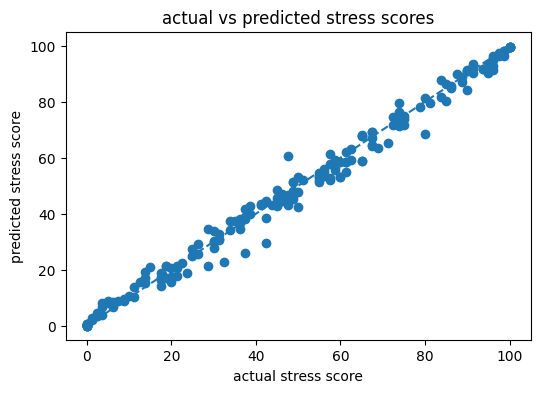

In [24]:
# import matplotlib for visualization
import matplotlib.pyplot as plt

# create an actual vs predicted stress score plot
plt.figure(figsize=(6, 4))

plt.scatter(y_test, y_pred)

# add a reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

# add labels and title
plt.xlabel("actual stress score")
plt.ylabel("predicted stress score")
plt.title("actual vs predicted stress scores")

# display the plot
plt.show()

The graph compares the actual stress scores with the scores predicted by the Random Forest model.

The points stay close to the reference line, which shows that the predicted values are close to the actual values. This visualization supports the high R2 score of 0.99 and shows that the model performs well on the test data.